# JavaScript Asynchronous Programming

A practical guide to writing asynchronous JavaScript using Promises and async/await — from understanding callback problems through creating and queuing promises to modern async/await syntax.

## Table of Contents

1. [Module 01: Understanding Promises](#module-01-understanding-promises)
2. [Module 02: Consuming Promises](#module-02-consuming-promises)
3. [Module 03: Queuing Promises](#module-03-queuing-promises)
4. [Module 04: Creating Promises](#module-04-creating-promises)
5. [Module 05: Iterating with Async/Await](#module-05-iterating-with-asyncawait)

In [1]:
from pathlib import Path
from IPython.display import HTML, display
import base64

def render_diagram(image_path, width=900):
    data = base64.b64encode(Path(image_path).read_bytes()).decode()
    display(HTML(f'<div style="text-align:center"><img src="data:image/png;base64,{data}" width="{width}"/></div>'))

## Module 01: Understanding Promises

Traces the history from raw callbacks to Promises, explaining why the callback pyramid is problematic and what Promises solve.

### The Race Condition Problem with XHR Callbacks

Before Promises, `XMLHttpRequest` callbacks were the standard way to make async requests. The code below fires two independent requests and tries to combine their results — but it contains a race condition:

```javascript
let statuses = [];
let xhr = new XMLHttpRequest();
xhr.open("GET", "http://localhost:3000/api/orderStatuses");
xhr.onload = () => {
  statuses = JSON.parse(xhr.responseText);
};
xhr.send();

let xhr2 = new XMLHttpRequest();
xhr2.open("GET", "http://localhost:3000/api/orders");
xhr2.onload = () => {
  const orders = JSON.parse(xhr2.responseText);
  const fullOrders = orders.map(o => {
    o.orderStatus = statuses.find(s => s.id === o.orderStatusId).description;
    return o;
  });
  showOrderList("#order-list", fullOrders);
};
xhr2.send();
```

**Problem:** If the `/api/orders` response arrives before `/api/orderStatuses`, `statuses` is still an empty array and the `find()` call throws.

#### Solving the Race Condition with Nested Calls

The naive fix is to move the second request _inside_ the first callback, forcing sequential execution:

```javascript
let statuses = [];
let xhr = new XMLHttpRequest();
xhr.open("GET", "http://localhost:3000/api/orderStatuses");
xhr.onload = () => {
  statuses = JSON.parse(xhr.responseText);
  let xhr2 = new XMLHttpRequest();
  xhr2.open("GET", "http://localhost:3000/api/orders");
  xhr2.onload = () => {
    const orders = JSON.parse(xhr2.responseText);
    const fullOrders = orders.map(o => {
      o.orderStatus = statuses.find(s => s.id === o.orderStatusId).description;
      return o;
    });
    showOrderList("#order-list", fullOrders);
  };
  xhr2.send();
};
xhr.send();
```

This works but introduces **nesting** — and once you need more than two sequential calls, the nesting grows into the Callback Pyramid of Doom.

### The Callback Pyramid of Doom

> A common problem that arises when a program uses many levels of nested indentation to control access to a function.

```javascript
a("test", (err, aResult) => {
  b(aResult, (err, bResult) => {
    c(bResult, (err, cResult) => {
      d(cResult);
    });
  });
});
```

#### Why Is the Pyramid Bad?

**1. Hidden bugs** — With four chained XHR callbacks, a wrong variable is easy to miss:

```javascript
xhr.onload = () => {
  xhr2.onload = () => {
    const order = JSON.parse(xhr2.responseText);
    let xhr3 = new XMLHttpRequest();
    xhr3.open("GET", `payments/${order.paymentId}`);
    xhr3.onload = () => {
      const payments = JSON.parse(xhr2.responseText); // bug: should be xhr3
      let xhr4 = new XMLHttpRequest();
      xhr4.open("GET", `paymentTypes/${payments.typeId}`);
      xhr4.onload = () => {
        const paymentType = JSON.parse(xhr4.responseText);
        setText(paymentType.description);
      };
    };
  };
};
```

**2. Error handling** — Every level needs its own `onerror` handler, multiplying boilerplate:

```javascript
xhr.onload  = () => { xhr2.onload  = () => { xhr3.onload  = () => { xhr4.onload  = () => {}; xhr4.onerror = () => {}; }; xhr3.onerror = () => {}; }; xhr2.onerror = () => {}; };
xhr.onerror = () => {};
```

### Introducing Promises

> **Promise** — an object that represents the eventual completion (or failure) of an asynchronous operation and its resulting value.
>
> — [MDN Web Docs](https://developer.mozilla.org/en-US/docs/Web/JavaScript/Reference/Global_Objects/Promise)

Promises replace nested callbacks with readable, chainable, flat async code.

#### Promise States

A Promise is always in one of three states:

| State | Meaning |
|---|---|
| **Pending** | The async operation has not yet completed |
| **Fulfilled** | The operation completed successfully |
| **Rejected** | The operation failed |

Once a promise leaves the Pending state it is **settled** — it cannot change state again.

**Settled vs. Resolved** — "Resolved" is sometimes used interchangeably with "fulfilled", but more precisely a resolved promise is one that is either fulfilled or has been chained to follow another promise's fate.

| Term | Meaning |
|---|---|
| **Settled** | No longer pending (either fulfilled or rejected) |
| **Resolved** | Settled, or following another promise |

#### Promises Are Not Lazy

Unlike lazy sequences (e.g. LINQ's `IEnumerable` in C#), a Promise executor runs **immediately** when the Promise is created — not when `.then()` is called.

#### Sample Project: Online Sporting Goods Retailer

The examples throughout this course use a mock REST API for an online sporting goods store. The API exposes these entities:

| | | |
|---|---|---|
| Addresses | Items | Orders |
| Users | ItemCategories | OrderStatuses |

## Module 02: Consuming Promises

Covers how to work with Promises returned by libraries like axios — using `.then()`, `.catch()`, `.finally()`, and chaining.

### Encountering Promises in the Wild

Most async APIs you encounter return Promises rather than accepting callbacks. `axios` is a common HTTP library that wraps `XMLHttpRequest` in Promises:

```javascript
import { get } from 'axios';
```

`.then()` is a method on the Promise object itself (not on axios). It registers a callback that runs when the promise is **fulfilled**:

```javascript
// Syntax
.then((result) => {
  // do stuff with the result
})

// In practice
axios.get("/api/orders")
  .then(({ data }) => {
    showOrderList("#order-list", data);  // called when promise is fulfilled
  });
// The promise is pending while the request is in flight
```

### Handling Errors with `.catch()`

`.catch()` registers a callback that runs when the promise is **rejected**:

```javascript
// Syntax
.catch((err) => {
  // do stuff with the error
})
```

### Chaining Promises

Both `.then()` and `.catch()` **return a new Promise**, so they can be chained:

```javascript
axios.get("/api/orders")
  .then(({ data }) => {
    showOrderList("#order-list", data);
    return "done";           // returned value becomes the next promise's resolved value
  })
  .then(result => console.log(result));  // logs "done"
```

A chain can interleave `.then()` and `.catch()` freely — a `.catch()` in the middle recovers from errors and the chain continues:

```javascript
promise
  .then()
  .catch()
  .then()
  .then()
  .catch()
```


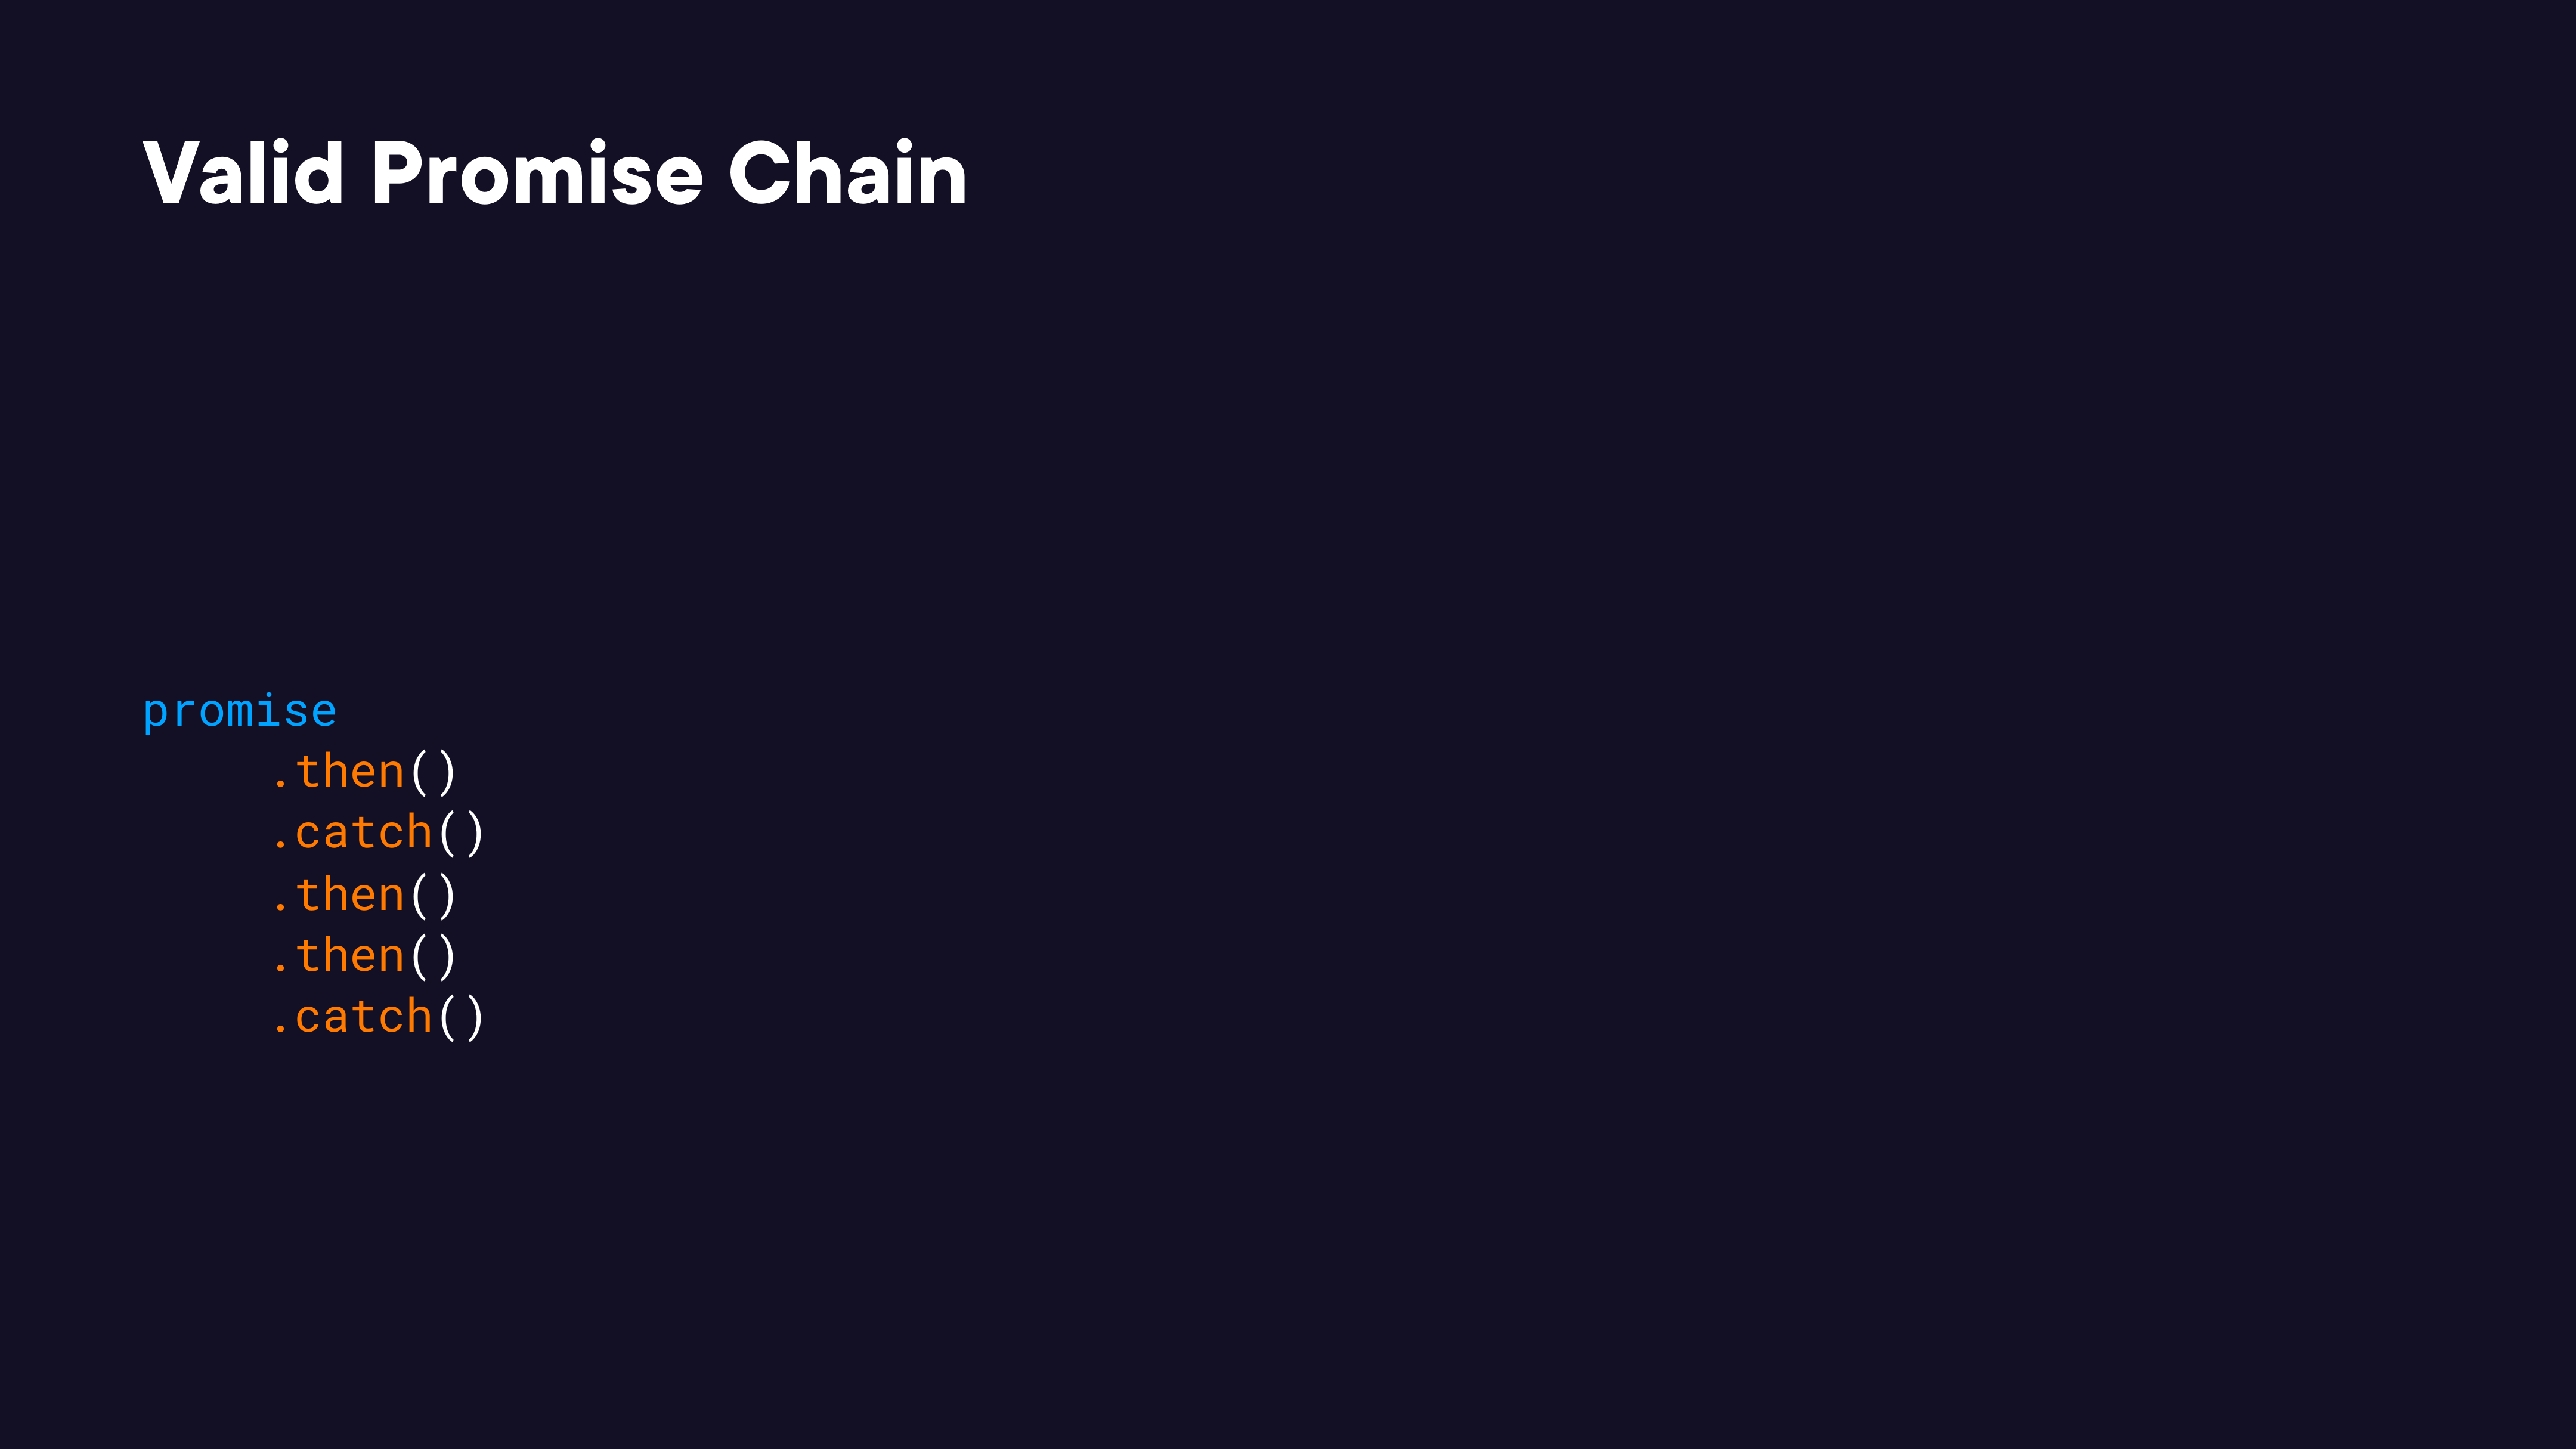

In [2]:
render_diagram(Path("assets/01-valid-promise-chain.png"))

### Running Code When a Promise Settles (`.finally()`)

A common use case is showing a loading indicator while a request is in flight, then hiding it regardless of success or failure. `.finally()` runs after the promise settles — whether fulfilled or rejected — making it ideal for teardown:

```javascript
showLoadingIndicator();
axios.get("/api/orders")
  .then(({ data }) => showOrderList("#order-list", data))
  .catch(err => showError(err))
  .finally(() => hideLoadingIndicator());
```

The loading indicator disappears whether the request succeeded or failed.

## Module 03: Queuing Promises

Covers the four static `Promise` methods for coordinating multiple promises: `all`, `allSettled`, `any`, and `race`.

### Synchronous vs. Asynchronous Loading

When loading several independent data sets (e.g. user status, customer types, job types), the synchronous approach waits for each response before starting the next request:


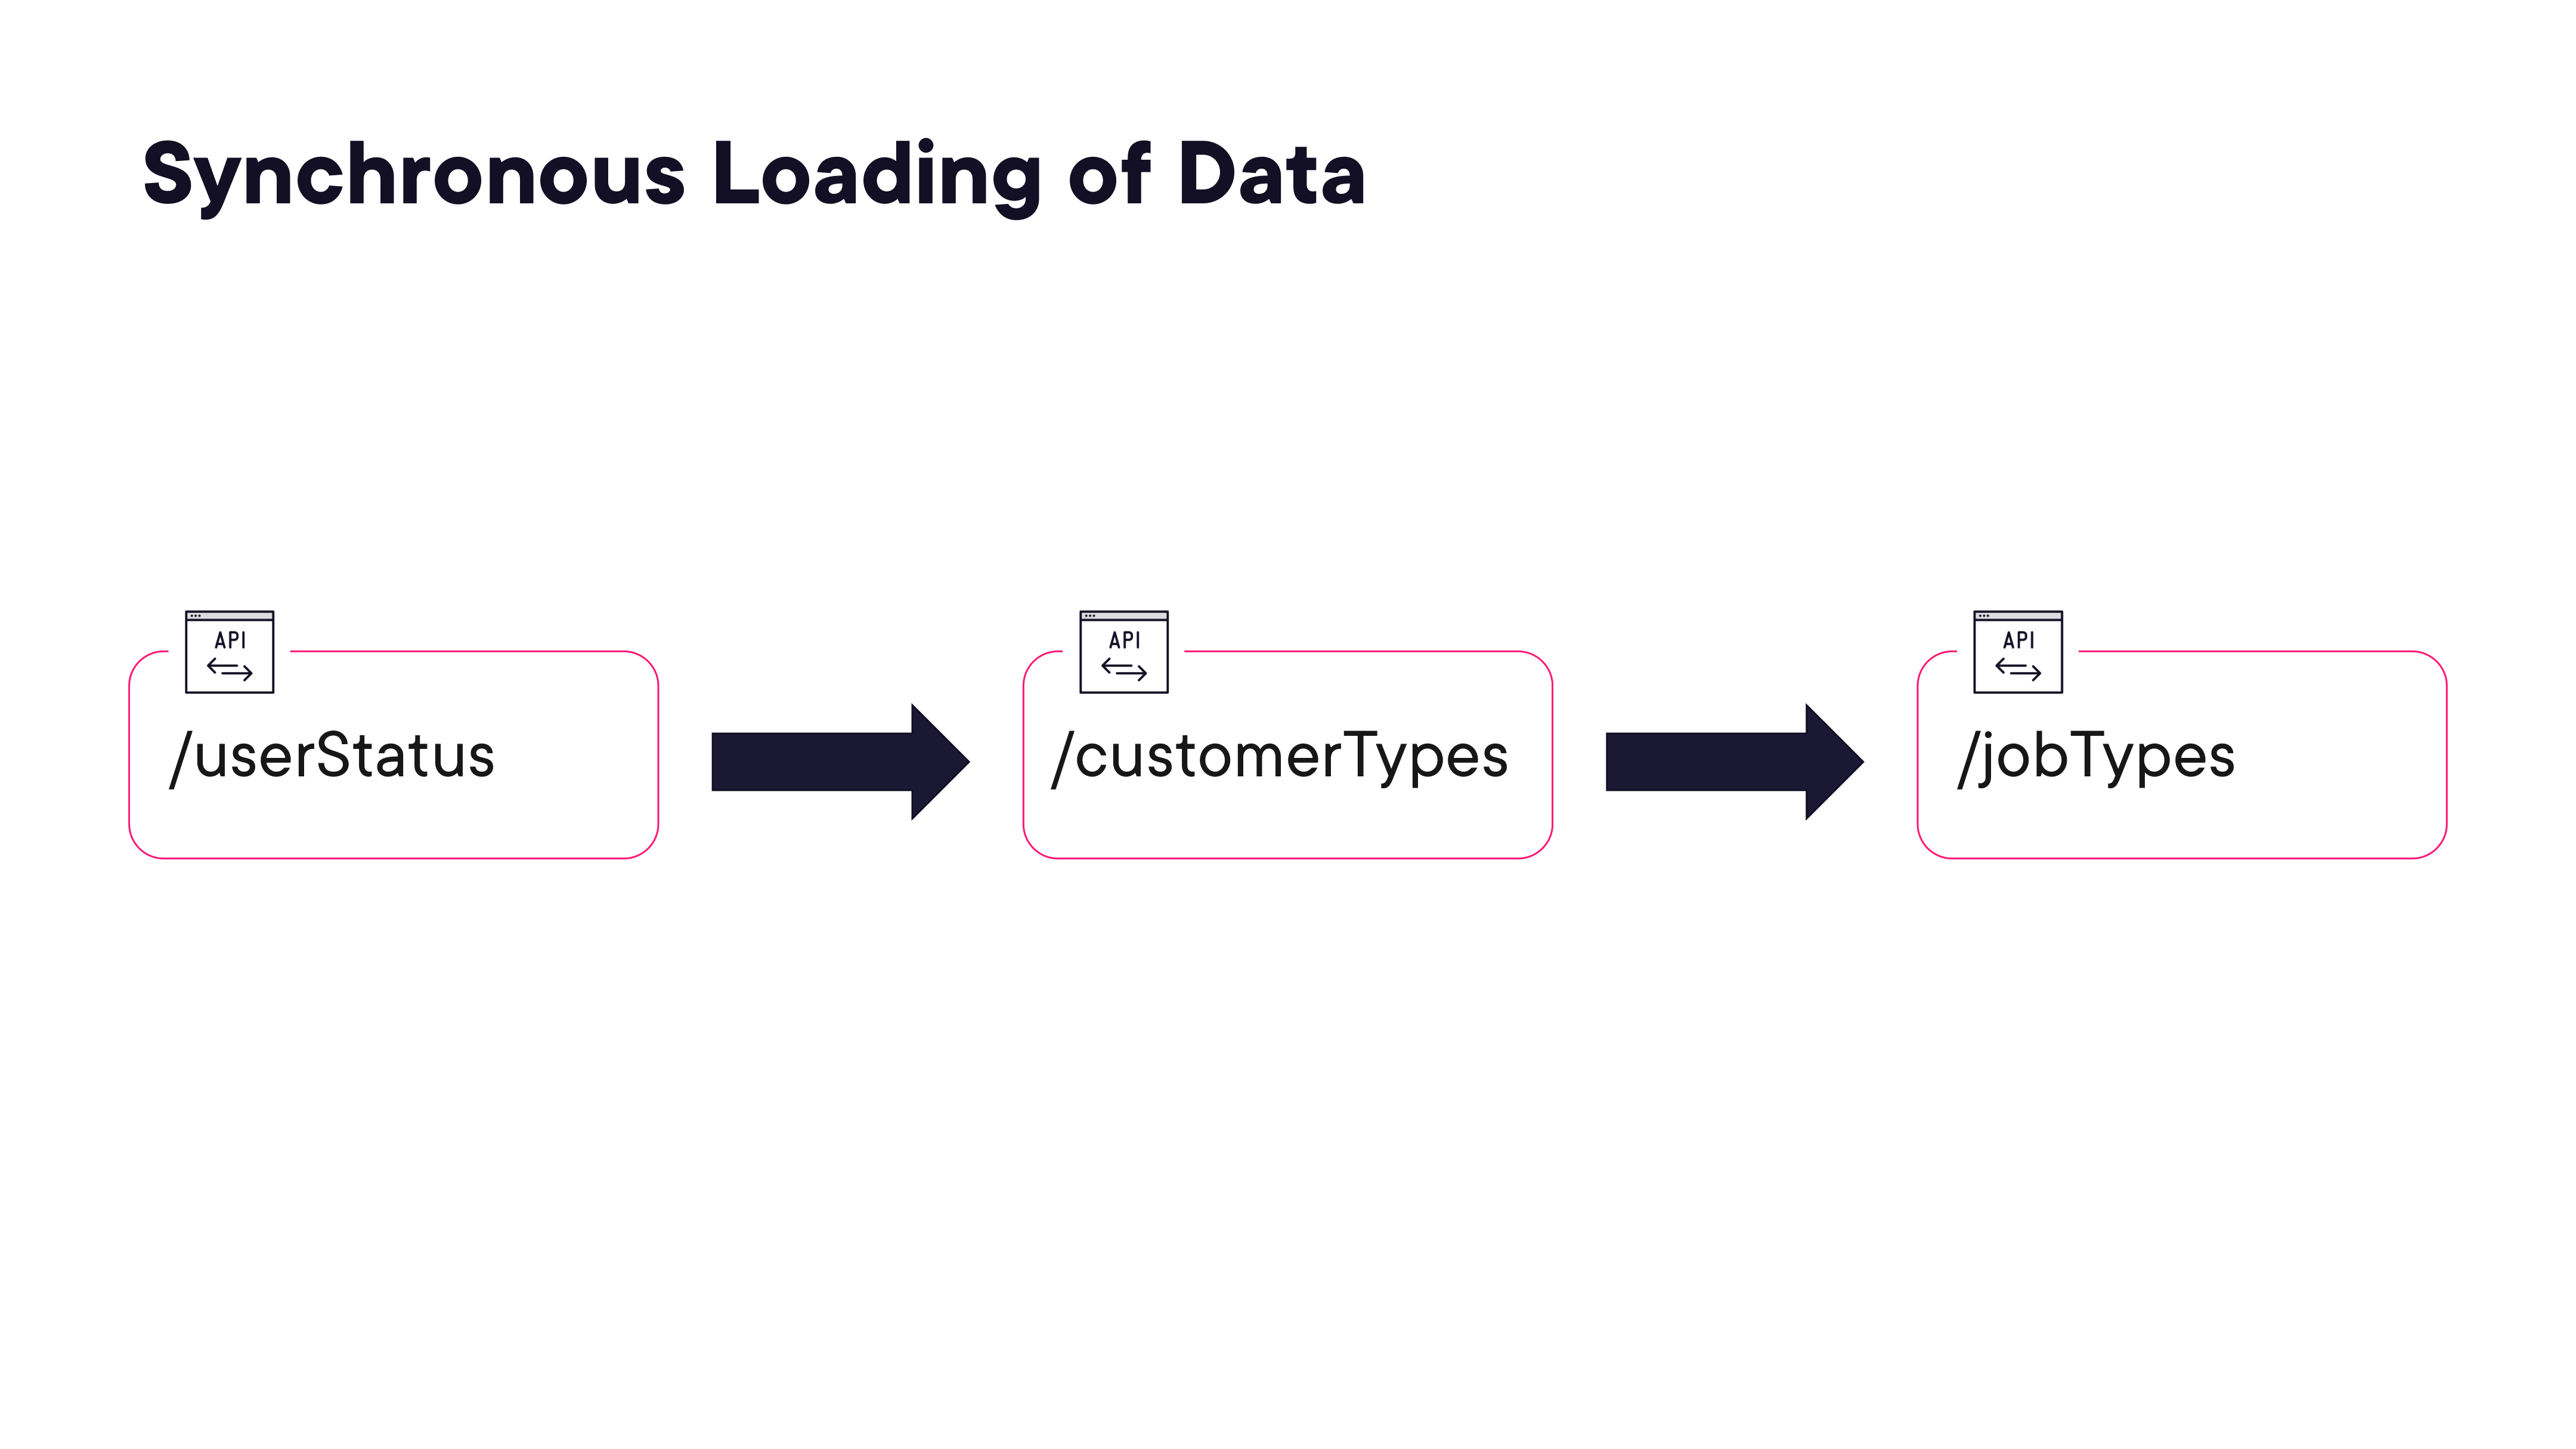

In [3]:
render_diagram(Path("assets/02-synchronous-loading.png"))

The async approach fires all three requests simultaneously and waits for them to complete in parallel, reducing total wait time to the slowest request:


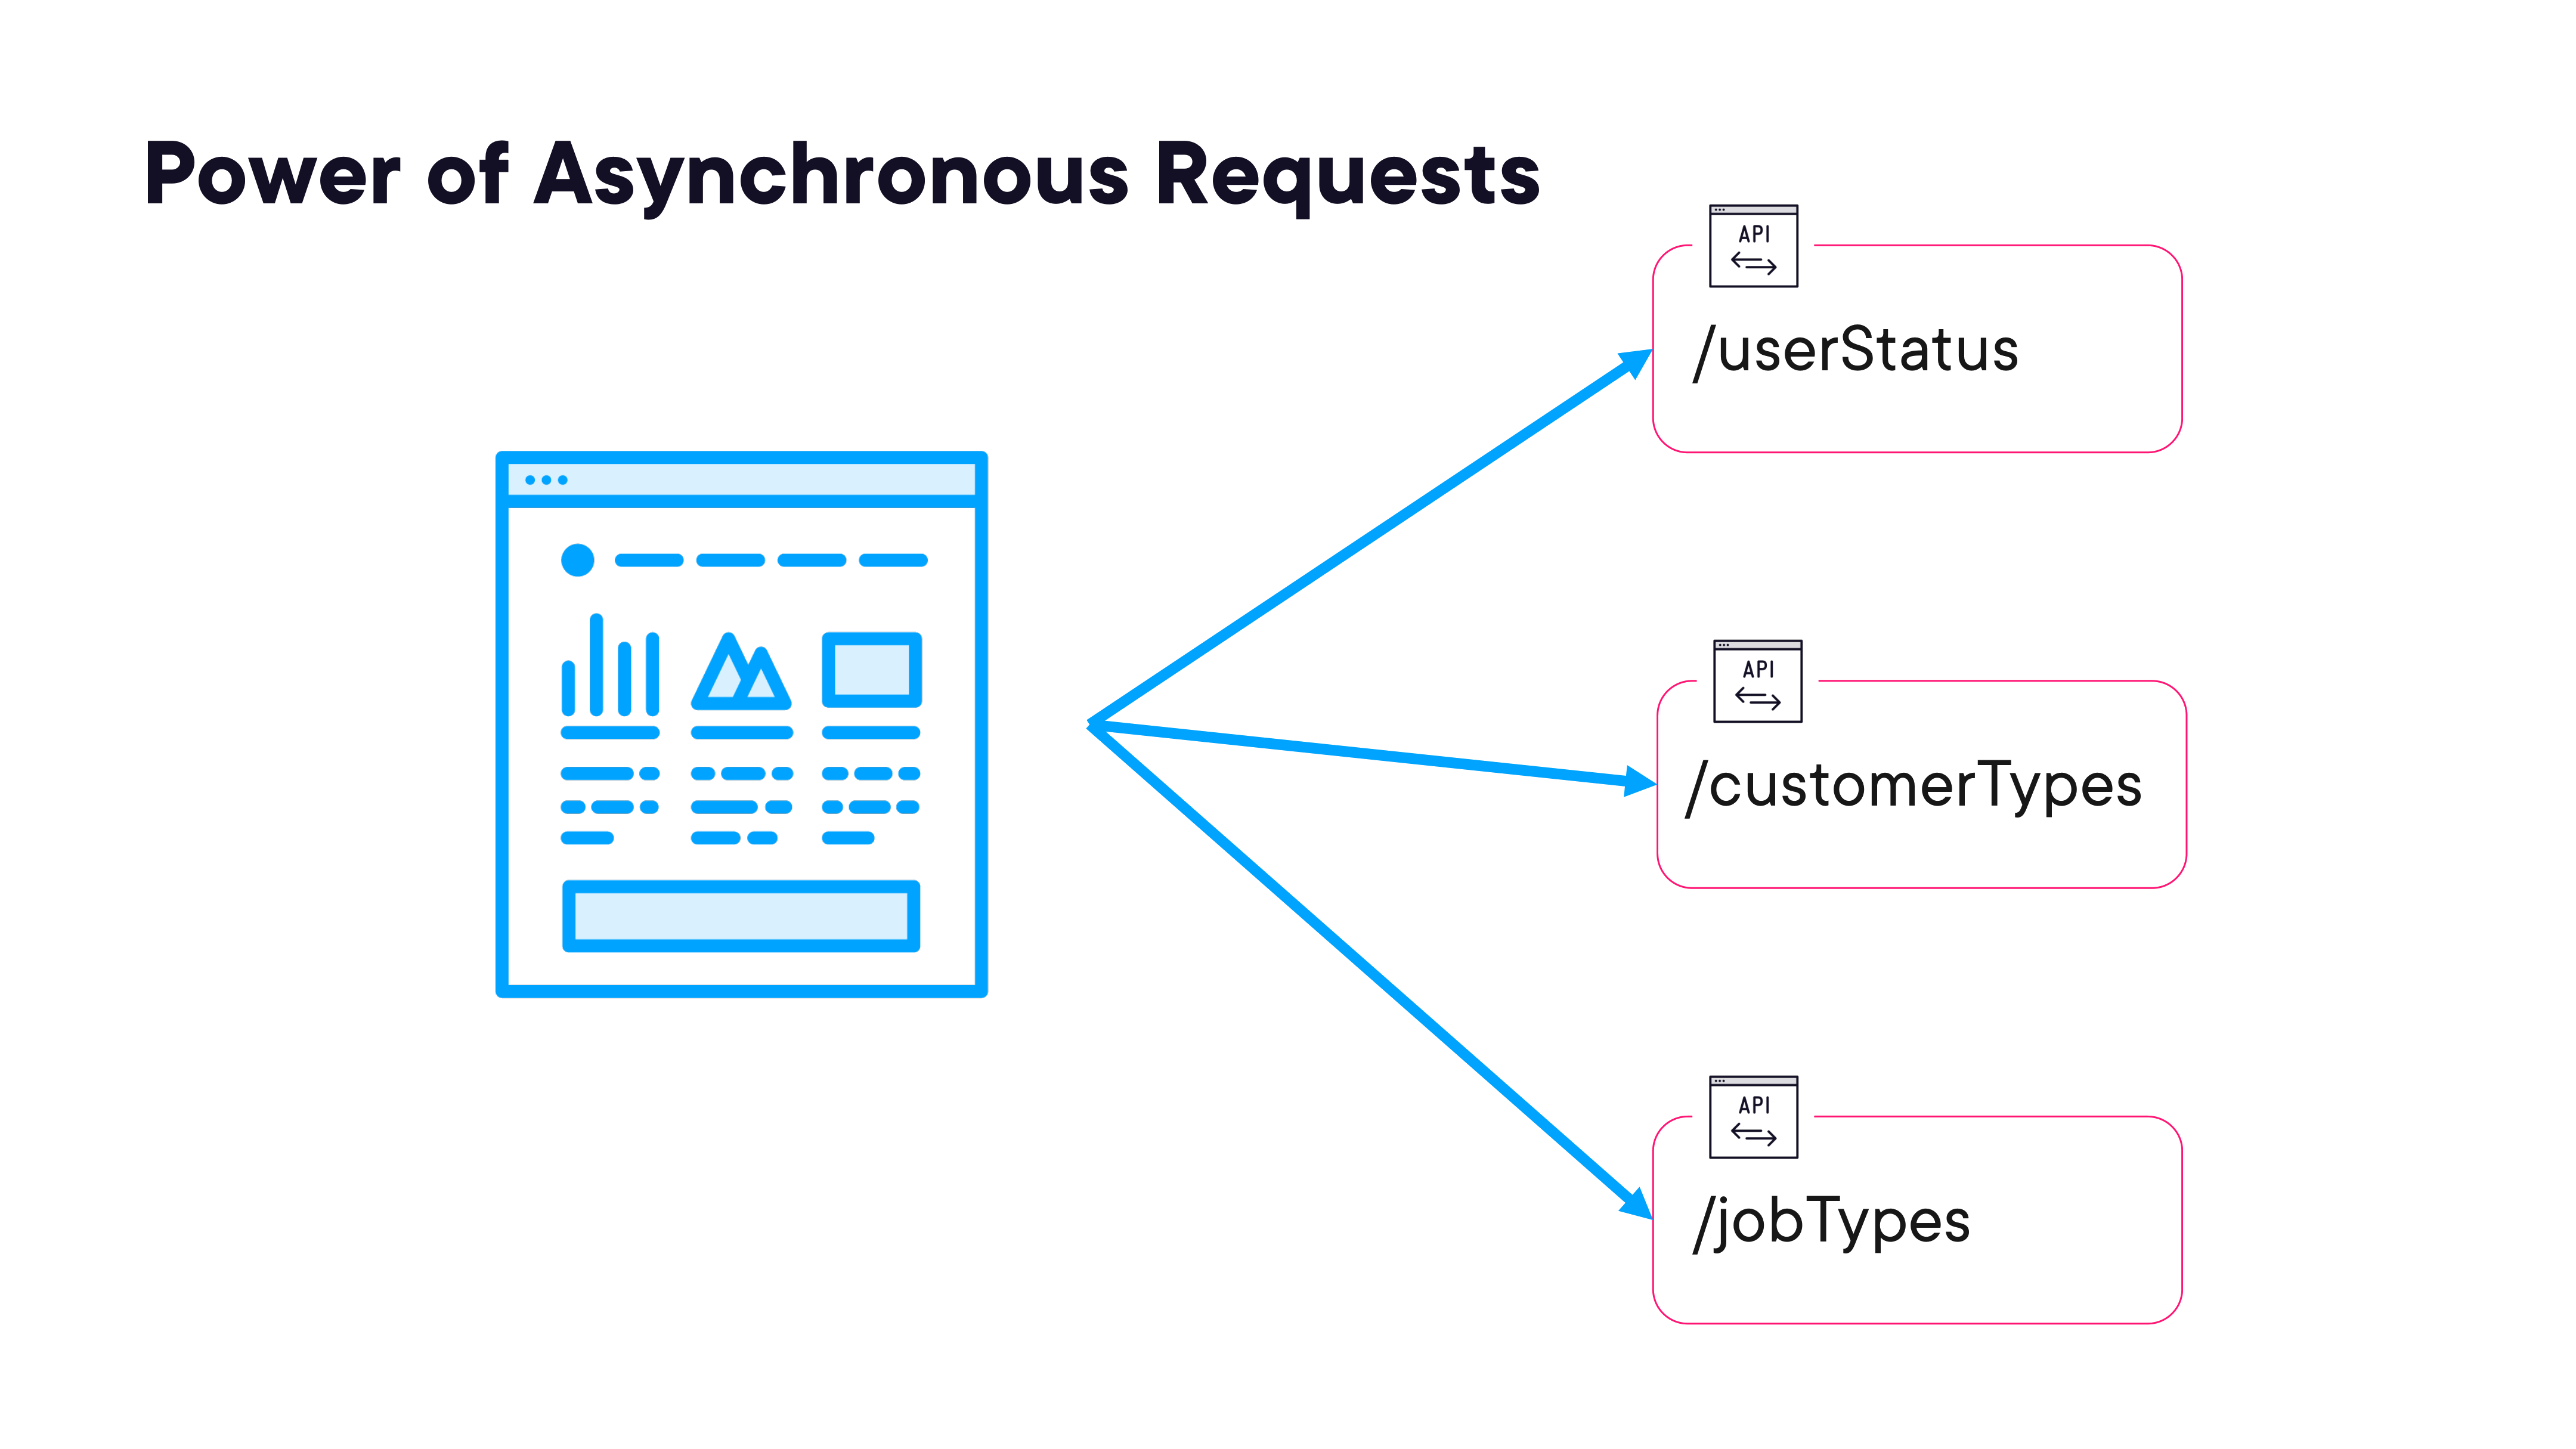

In [4]:
render_diagram(Path("assets/03-async-parallel-loading.png"))

### Promise.all()

`Promise.all()` accepts an array of promises and returns a single promise that:
- **Fulfills** when every promise in the array fulfills — returns an array of all results in input order.
- **Rejects** as soon as any one promise rejects — short-circuits immediately.

Analogous to `Array.every()` — succeeds only if all succeed.

```javascript
Promise.all([
  axios.get("/userStatus"),
  axios.get("/customerTypes"),
  axios.get("/jobTypes"),
])
.then(([userStatus, customerTypes, jobTypes]) => {
  // all three resolved
})
.catch(err => {
  // at least one rejected
});
```

### Promise.allSettled()

`Promise.allSettled()` waits for **all** promises to settle (fulfilled or rejected) and always fulfills with an array of result objects — it never rejects:

```javascript
// Each result object has one of these shapes:
{ status: 'fulfilled', value: {} }
{ status: 'rejected',  reason: {} }
```

Because it never rejects, `.catch()` is not strictly required — though it is still recommended as a safety net. Use `allSettled` when you want all results regardless of individual failures.

### Analogies with Array Methods

| Promise method | Array analogy | Behaviour |
|---|---|---|
| `Promise.all()` | `Array.every()` | True only if every item succeeds |
| `Promise.any()` | `Array.some()` | True if at least one succeeds |

### Promise.any()

`Promise.any()` resolves with the **first fulfilled** value. It only rejects if **all** promises reject.

```javascript
Promise.any([promise1, promise2])
  .then(value => {}) // first one to fulfill wins
```

**When to use it:** Multiple redundant endpoints — use whichever responds first.

**Key difference from `Promise.all()`:**

| | `Promise.all()` | `Promise.any()` |
|---|---|---|
| Input | Array of promises | Array of promises |
| Returns | Array of all results | Single value (first success) |
| Rejects when | First rejection | All reject |

### Promise.race()

`Promise.race()` resolves or rejects with the **first settled** promise — success or failure, whichever comes first.

```javascript
Promise.race([possiblyLongRunningRequest, timeout])
  .then(val => showData(val))
  .catch(() => showTryAgainLater());
```

`race` requires both `.then()` and `.catch()` because it can settle either way. It is rarely used in practice but is useful for implementing timeouts.

**`Promise.any()` vs `Promise.race()`:**

| | `Promise.any()` | `Promise.race()` |
|---|---|---|
| Input | Array of promises | Array of promises |
| Returns | Single value | Single value |
| Settles on | First **fulfilled** or all rejected | First **settled** (fulfilled or rejected) |

### Summary: Promise Queuing Functions

| Method | Settles when |
|---|---|
| `Promise.all()` | All fulfilled, or first rejection |
| `Promise.allSettled()` | All settled |
| `Promise.any()` | First fulfilled, or all rejected |
| `Promise.race()` | First settled |

## Module 04: Creating Promises

Explains how to construct promises from scratch using `new Promise()`, the executor function, and the `resolve`/`reject` callbacks.

### The `new Promise()` Constructor

A promise is created with `new Promise(executorFn)`. The executor function runs immediately (eager execution):

```javascript
// Most basic form — promise stays pending forever
const tmp = new Promise(() => {});

// Executor with async work
const tmp = new Promise(() => {
  setTimeout(() => {
    console.log("timeout");
  }, 1500);
});
// "timeout" is logged after 1.5 s, but the promise is still pending
// because resolve() was never called
```

### Fulfilling a Promise with `resolve()`

Pass `resolve` as the first parameter of the executor. Calling it transitions the promise from **Pending** to **Fulfilled** and passes a value to `.then()`:

```javascript
const tmp = new Promise((resolve) => {
  setTimeout(() => {
    resolve("timeout");  // fulfills the promise with the string "timeout"
  }, 1500);
})
.then((data) => console.log(data));  // logs "timeout" after 1.5 s
```

Data you can resolve with includes: status codes, response headers, blocks of data, etc. — anything relevant to the caller.

### Promise State Is Final

Once a promise is settled, calling `resolve()` or `reject()` again has **no effect**. This is why using `setInterval` instead of `setTimeout` does not cause the `.then()` to run multiple times:

```javascript
// setInterval keeps firing, but only the first resolve() call matters
const tmp = new Promise((resolve) => {
  setInterval(() => {
    resolve("timeout");  // only the first call has any effect
  }, 1500);
})
.then((data) => console.log(data));  // logs "timeout" exactly once
```

### Rejecting a Promise

Pass `reject` as the second parameter of the executor. Calling it transitions the promise to **Rejected** and passes a reason to `.catch()`:

```javascript
new Promise((resolve, reject) => {
  if (something_good) {
    resolve();
  } else {
    reject();
  }
});
```

You control what data gets passed to `.then()` (via `resolve`) and `.catch()` (via `reject`).

### Wrapping XHR in a Promise

Here is a complete example of wrapping a raw XHR request in a Promise, showing how to decide when to resolve vs. reject:

```javascript
new Promise((resolve, reject) => {
  var xhr = new XMLHttpRequest();
  xhr.open("GET", url);
  xhr.onload = () => {
    if (xhr.status === 200) {
      resolve(xhr.responseText);  // success path
    } else {
      reject(xhr.statusText);     // HTTP error path
    }
  };
  xhr.onerror = () => {
    reject("Request failed!");    // network error path
  };
  xhr.send();
});
```

How you handle resolve and reject is a design decision — it depends on what the caller needs to know.

## Module 05: Iterating with Async/Await

Introduces the `async`/`await` syntax — syntactic sugar over Promises that makes async code read like synchronous code.

### What Is Async/Await?

> **Syntactic sugar** — syntax within a programming language that is designed to make things easier to read or to express.

`async`/`await` is syntactic sugar for Promises. It does not introduce new capabilities — your knowledge of Promises carries over completely.

### The `async` and `await` Keywords

#### Defining an `async` function

The `async` keyword marks a function as asynchronous. An async function **always returns a Promise**:

```javascript
// Standard function declaration
async function getNames() {
  return [];
}

// Arrow function
const getNames = async () => {
  return [];
};
```

#### The `await` keyword

`await` pauses execution inside an `async` function until the awaited promise settles, then returns its resolved value.

**Two rules for `await`:**
1. Must be used inside an `async` function.
2. Only blocks the **current function** — other code outside the async function continues running.

```javascript
const getNames = async () => {
  await someFunc();        // waits here inside getNames
  doSomethingElse();       // runs after someFunc resolves
};

getNames();       // starts the async function (non-blocking)
getAddresses();   // runs immediately, does not wait for getNames
```


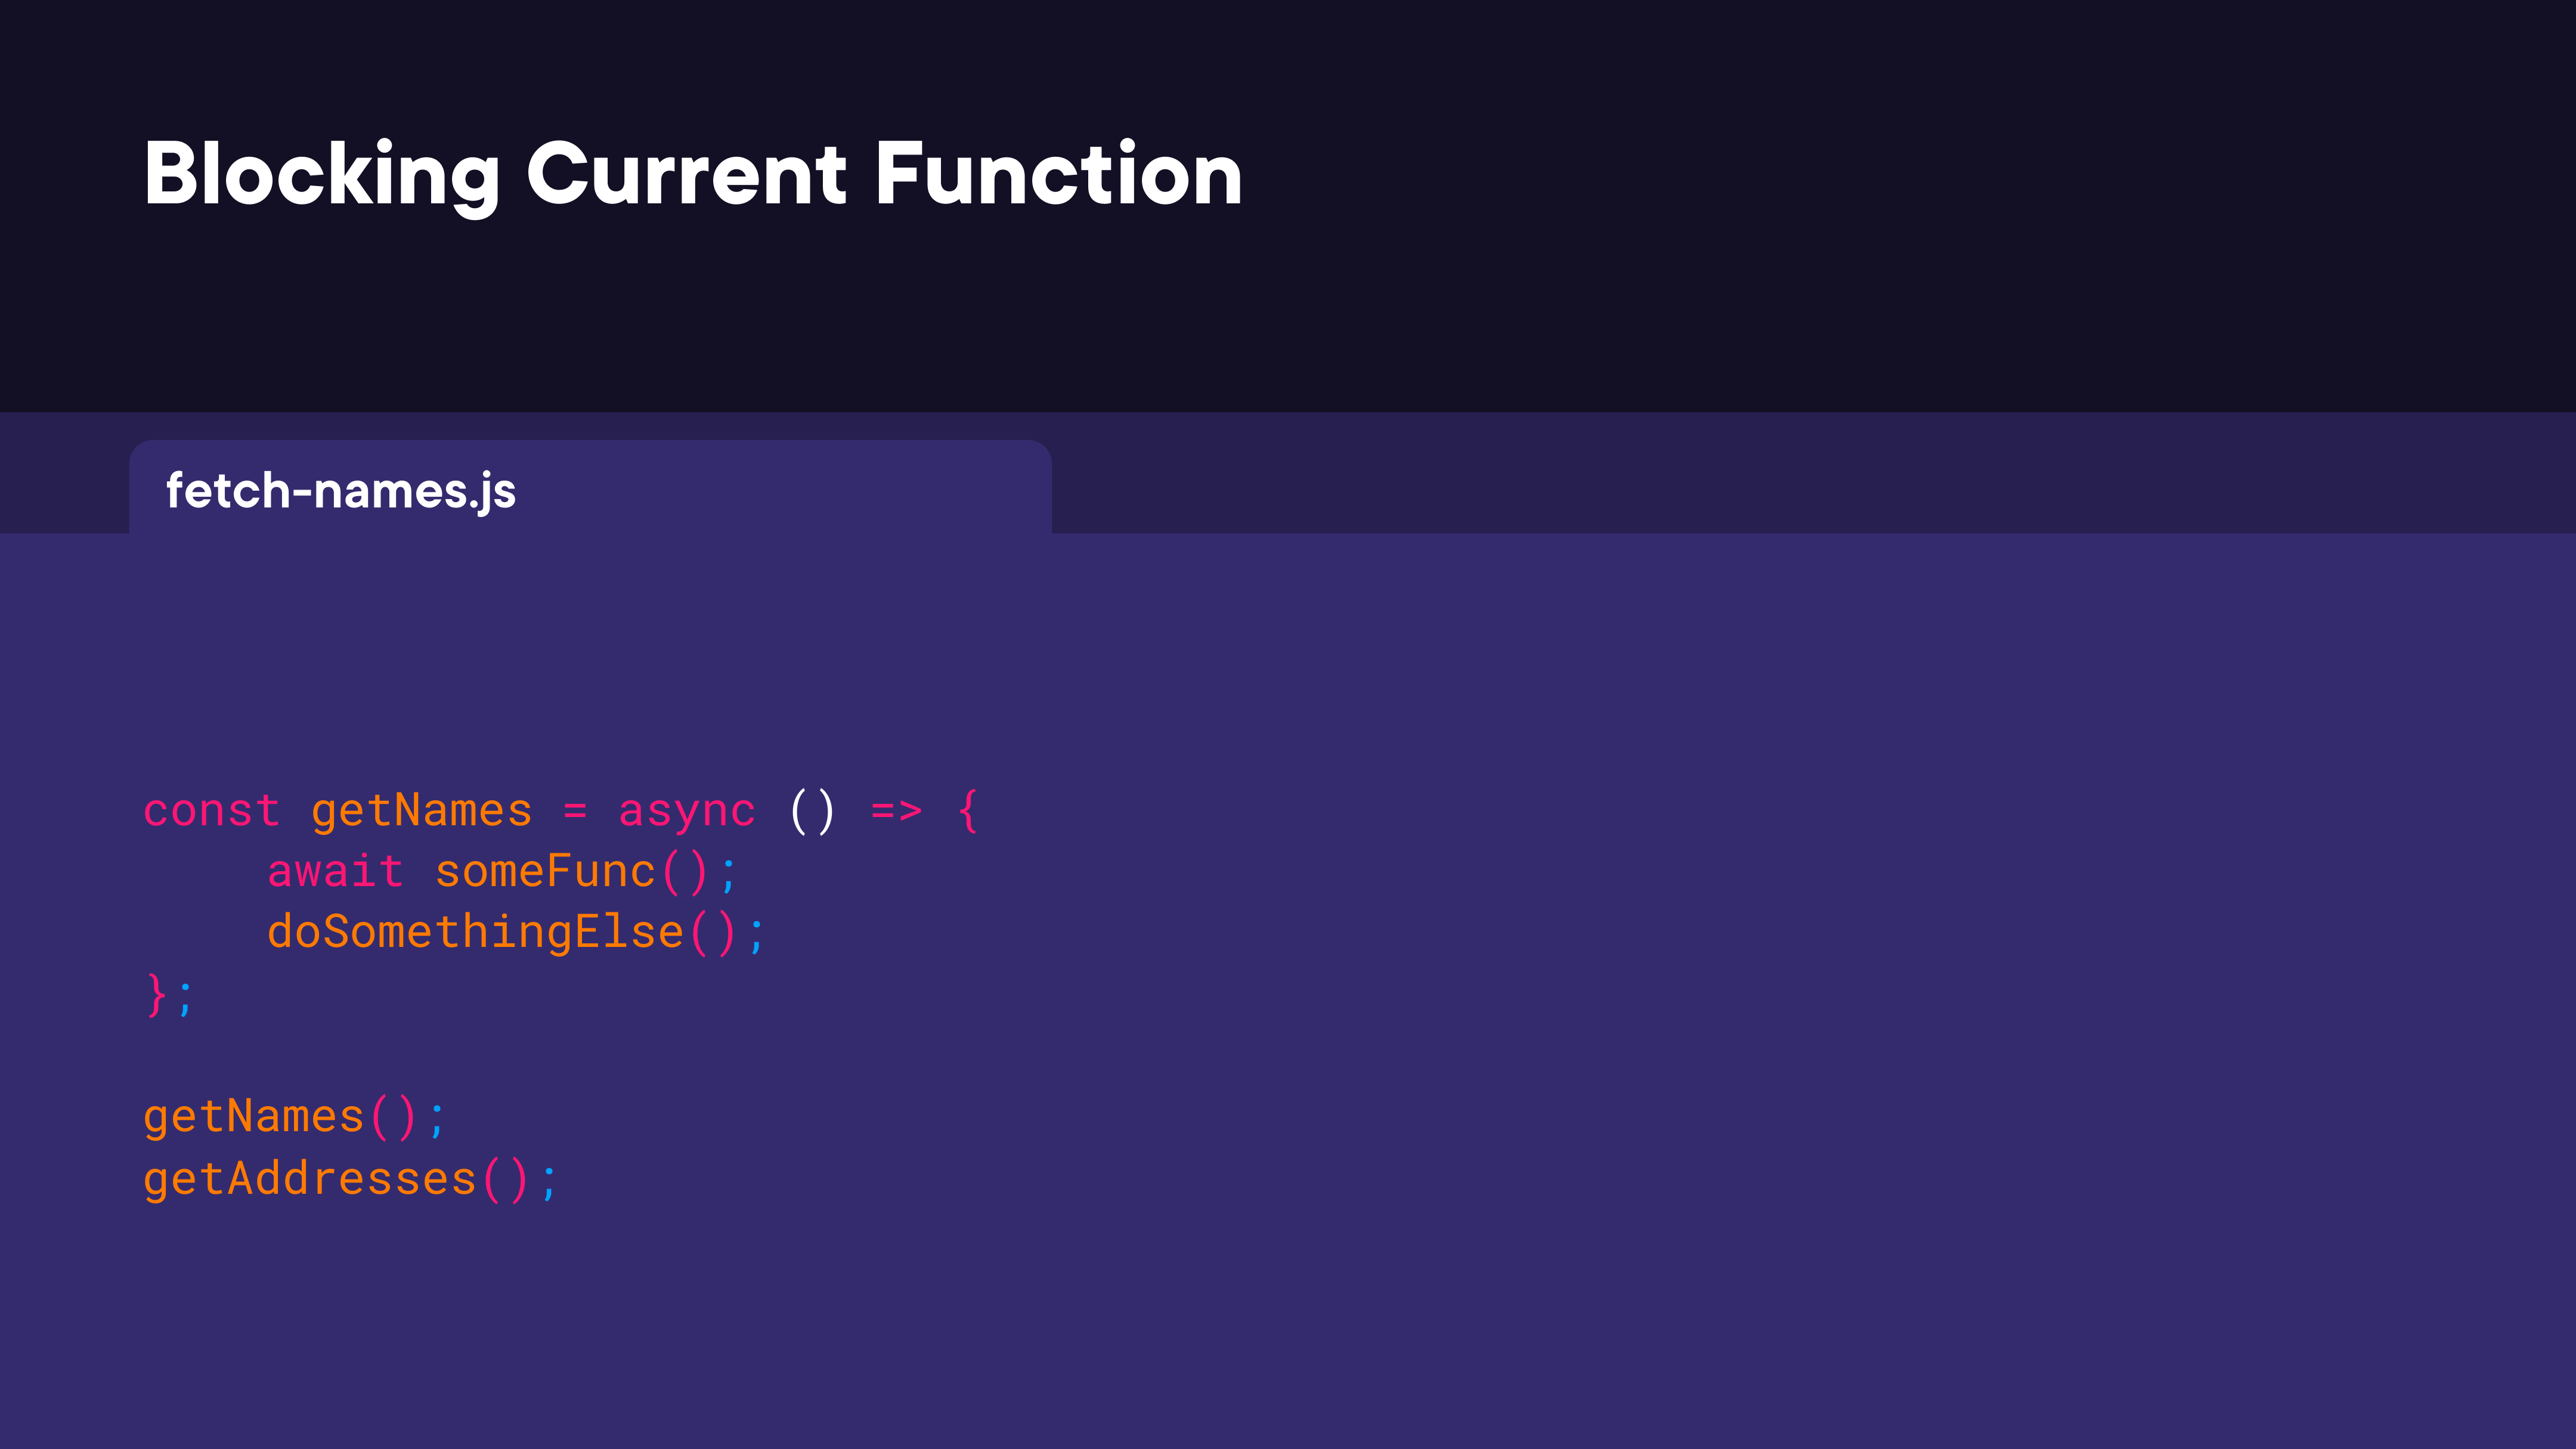

In [5]:
render_diagram(Path("assets/04-async-blocking-scope.png"))

### Async/Await vs. Promise Chains

The same async operation written two ways:

```javascript
// Promise style
axios.get("/api/orders/")
  .then(({ data }) => {
    showOrderList("#orders", data);
  });

// Async/await style
const tmp = async function() {
  const { data } = await axios.get("/api/orders");
  showOrderList("#orders", data);
};
```

The async/await version reads top-to-bottom like synchronous code.

### Error Handling with Async/Await

Use `try`/`catch` instead of `.catch()`:

```javascript
const tmp = async function() {
  try {
    const { data } = await axios.get("/api/orders");
    showOrderList("#orders", data);
  } catch (err) {
    showError(err);
  }
};
```

### "Chaining" with Async/Await

Sequential dependent calls that required `.then()` chaining are now just sequential `await` statements:

```javascript
// Promise chaining
axios.get("http://localhost:3000/api/orderStatuses")
  .then(({ data }) => {
    statuses = data;
    return axios.get("http://localhost:3000/api/orders");
  })
  .then(({ data }) => {
    // do stuff
  });

// Async/await equivalent
const { data: statuses } = await axios.get("http://localhost:3000/api/orderStatuses");
const { data } = await axios.get("http://localhost:3000/api/orders");
// do stuff
```

### Awaiting Concurrent (Parallel) Requests

Sequential `await` calls run one at a time. To run multiple independent requests in parallel, combine `async`/`await` with `Promise.all()`:

```javascript
// Sequential — slower (waits for each before starting the next)
const { data: statuses }      = await axios.get("/api/orderStatuses");
const { data: customerTypes } = await axios.get("/api/customerTypes");
const { data: jobTypes }      = await axios.get("/api/jobTypes");

// Parallel — faster (all three fire simultaneously)
const [statusRes, customerRes, jobRes] = await Promise.all([
  axios.get("/api/orderStatuses"),
  axios.get("/api/customerTypes"),
  axios.get("/api/jobTypes"),
]);
```

### Review

```javascript
// Promise states
// Pending → Fulfilled (resolve called)
// Pending → Rejected  (reject called)

// Creating a promise
const tmp = new Promise((res, rej) => {});

// Using async/await
const tmp = async function () {
  const result = await axios.get("/api/orders");
};
```